# Entrega N° 1 - Data Science II: Machine Learning para la Ciencia de Datos (Diplomaturas)

## Proyecto: Modelado Predictivo y Enriquecimiento Biológico en Adopción de Mascotas

### Motivación y audiencia

#### Motivación

La sobrepoblación en refugios y centros de rescate animal es un desafío logístico y de bienestar crítico. Predecir qué animales tardarán más en ser adoptados permite a las organizaciones asignar recursos de marketing de manera eficiente y gestionar su capacidad instalada. Este proyecto analiza un registro transaccional de mascotas en adopción, cruzando variables de presentación (fotos, edad, color) con datos biológicos reales obtenidos mediante una API externa (esperanza de vida, temperamento, tamaño promedio según raza). El objetivo es identificar los principales predictores de la velocidad de adopción (medida en días) para optimizar las estrategias de rescate y ubicación.

#### Audiencia

Dirigido a roles ejecutivos de fundaciones animalistas, directores logísticos de refugios, estrategas de marketing de ONG y médicos veterinarios enfocados en bienestar animal y medicina poblacional.

#### Preguntas / hipótesis

**1 - El impacto de la biología (API):** ¿Los perros y gatos de razas con mayor expectativa de vida biológica promedio (extraída de la API) son adoptados más rápido que las razas de vida corta?

**2 - El impacto visual:** ¿El volumen de fotografías en el perfil de una mascota acelera estadísticamente su adopción, neutralizando factores como la edad avanzada?

**3 - Preferencia de tamaño:** ¿Existe un sesgo de adopción medible hacia los animales genéticamente más pequeños (según la API) frente a razas de tamaño grande o gigante?

**4 - Factor edad al ingreso:** ¿Cuál es el punto de quiebre (en meses de edad) donde la probabilidad de adopción temprana cae drásticamente?

In [226]:
# Importaciones necesarias

import pandas as pd
import requests
import os
from dotenv import load_dotenv
import re
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Etapa 1 - Dataset

### Carga del dataset original

In [227]:
# Cargar el dataset transaccional desde la subcarpeta 'dataset'
df_mascotas = pd.read_csv('dataset/AdopcionMascotas.csv')

### Información relevante del dataset original

In [228]:
df_mascotas.columns

Index(['Type', 'Name', 'Age', 'Breed1', 'Breed2', 'Gender', 'Color1', 'Color2',
       'Color3', 'MaturitySize', 'FurLength', 'Vaccinated', 'Dewormed',
       'Sterilized', 'Health', 'Quantity', 'Fee', 'State', 'RescuerID',
       'VideoAmt', 'Description', 'PetID', 'PhotoAmt', 'AdoptionSpeed'],
      dtype='str')

In [229]:
df_mascotas.info()

<class 'pandas.DataFrame'>
RangeIndex: 14993 entries, 0 to 14992
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Type           14993 non-null  int64  
 1   Name           13728 non-null  str    
 2   Age            14993 non-null  int64  
 3   Breed1         14993 non-null  int64  
 4   Breed2         14993 non-null  int64  
 5   Gender         14993 non-null  int64  
 6   Color1         14993 non-null  int64  
 7   Color2         14993 non-null  int64  
 8   Color3         14993 non-null  int64  
 9   MaturitySize   14993 non-null  int64  
 10  FurLength      14993 non-null  int64  
 11  Vaccinated     14993 non-null  int64  
 12  Dewormed       14993 non-null  int64  
 13  Sterilized     14993 non-null  int64  
 14  Health         14993 non-null  int64  
 15  Quantity       14993 non-null  int64  
 16  Fee            14993 non-null  int64  
 17  State          14993 non-null  int64  
 18  RescuerID      14

### IA: Uso un agente de IA para que me genere un diccionario de columnas del dataset, nombre de las columnas, traducción, descripción y dtype

### Diccionario de columnas

| Columna original | Traducción | Descripción breve | Non-Null Count | Dtype |
|---|---|---|---|---|
| `Type` | Tipo | Especie de la mascota (perro o gato). | 14993 | int64 |
| `Name` | Nombre | Nombre de la mascota. | 13728 | str |
| `Age` | Edad | Edad en meses. | 14993 | int64 |
| `Breed1` | Raza principal | Raza principal de la mascota. | 14993 | int64 |
| `Breed2` | Raza secundaria | Segunda raza, si es mestiza. | 14993 | int64 |
| `Gender` | Sexo | Sexo de la mascota. | 14993 | int64 |
| `Color1` | Color 1 | Primer color del pelaje. | 14993 | int64 |
| `Color2` | Color 2 | Segundo color del pelaje. | 14993 | int64 |
| `Color3` | Color 3 | Tercer color del pelaje. | 14993 | int64 |
| `MaturitySize` | Tamaño adulto | Tamaño que alcanzará de adulto. | 14993 | int64 |
| `FurLength` | Largo del pelaje | Longitud del pelo. | 14993 | int64 |
| `Vaccinated` | Vacunado | Indica si está vacunada. | 14993 | int64 |
| `Dewormed` | Desparasitado | Indica si está desparasitada. | 14993 | int64 |
| `Sterilized` | Esterilizado | Indica si está esterilizada. | 14993 | int64 |
| `Health` | Salud | Estado de salud general. | 14993 | int64 |
| `Quantity` | Cantidad | Número de mascotas en la publicación. | 14993 | int64 |
| `Fee` | Tarifa | Costo de la adopción. | 14993 | int64 |
| `State` | Estado/Región | Ubicación geográfica de la mascota. | 14993 | int64 |
| `RescuerID` | ID del rescatista | Identificador de quien la rescató. | 14993 | str |
| `VideoAmt` | Cantidad de videos | Videos incluidos en la publicación. | 14993 | int64 |
| `Description` | Descripción | Texto descriptivo de la mascota. | 14980 | str |
| `PetID` | ID de la mascota | Identificador único de la mascota. | 14993 | str |
| `PhotoAmt` | Cantidad de fotos | Fotos incluidas en la publicación. | 14993 | float64 |
| `AdoptionSpeed` | Velocidad de adopción | Días hasta la adopción, codificados de 0 a 4. | 14993 | int64 |

### Visualización del dataset original

In [230]:
print(f"Total de mascotas en el registro: {len(df_mascotas)}")
df_mascotas.head(5)

Total de mascotas en el registro: 14993


,Type,Name,Age,Breed1,Breed2,Gender,Color1,Color2,Color3,MaturitySize,...,Health,Quantity,Fee,State,RescuerID,VideoAmt,Description,PetID,PhotoAmt,AdoptionSpeed
0,2,Nibble,3,299,0,1,1,7,0,1,...,1,1,100,41326,8480853f516546f6cf33aa88cd76c379,0,Nibble is a 3+ month old ball of cuteness. He ...,86e1089a3,1.0,2
1,2,No Name Yet,1,265,0,1,1,2,0,2,...,1,1,0,41401,3082c7125d8fb66f7dd4bff4192c8b14,0,I just found it alone yesterday near my apartm...,6296e909a,2.0,0
2,1,Brisco,1,307,0,1,2,7,0,2,...,1,1,0,41326,fa90fa5b1ee11c86938398b60abc32cb,0,Their pregnant mother was dumped by her irresp...,3422e4906,7.0,3
3,1,Miko,4,307,0,2,1,2,0,2,...,1,1,150,41401,9238e4f44c71a75282e62f7136c6b240,0,"Good guard dog, very alert, active, obedience ...",5842f1ff5,8.0,2
4,1,Hunter,1,307,0,1,1,0,0,2,...,1,1,0,41326,95481e953f8aed9ec3d16fc4509537e8,0,This handsome yet cute boy is up for adoption....,850a43f90,3.0,2


## Etapa 2 - Datos desde API

### Conexión a la API

#### Enriquecimiento de datos (fuentes externas)

Para trascender el análisis transaccional básico, el dataset estático del refugio se enriqueció consumiendo dos servicios web públicos: The Dog API y The Cat API. La integración de estas APIs permitió extraer la "verdad biológica" de los animales de raza pura (específicamente su esperanza de vida y peso estructural promedio). Cruzar la data logística con esta genética estandarizada fue clave para evaluar, con rigor científico, si la longevidad o el tamaño físico influyen realmente en las decisiones de los adoptantes.

📌 Nota Metodológica: Gestión de Credenciales y Caché Local
Para garantizar la reproducibilidad total de este Jupyter Notebook durante su evaluación, sin comprometer la seguridad de las credenciales privadas (API Keys alojadas en un archivo .env local y excluidas vía .gitignore), se ha implementado un mecanismo de Caché Local en este bloque de código.

Flujo de ejecución:

Validación de entorno: El script verifica primero la existencia del archivo dataset/biologia_api_cache.csv.

Entorno de Evaluación (Lectura Local): Al descargar este repositorio desde GitHub, ya se contará con el archivo CSV generado. El código lo detectará automáticamente, omitirá la petición HTTP a la API y cargará el Dataframe directamente desde el disco. Esto elimina la necesidad de configurar variables de entorno o crear cuentas en The Dog/Cat API para probar el código.

Entorno de Desarrollo (Ingesta Activa): Si el archivo no existe (ej. en la primera ejecución de desarrollo), el script consume las variables de entorno, establece conexión segura con las APIs, estructura los JSON y genera dinámicamente el archivo CSV para futuras ejecuciones.

In [231]:

ruta_cache = 'dataset/biologia_api_cache.csv'

# Se verifica si ya se descargaron los datos anteriormente
if os.path.exists(ruta_cache):
    print("Archivo caché encontrado. Cargando datos biológicos desde CSV local (sin requerir API Keys)...")
    df_biologia = pd.read_csv(ruta_cache)
    print(f"Total de razas cargadas desde caché: {len(df_biologia)}")

else:
    print("No se encontró caché local. Conectando a The Dog/Cat API (Secure Mode)...")
    load_dotenv()
    API_KEY_DOG = os.getenv("DOG_API_KEY")
    API_KEY_CAT = os.getenv("CAT_API_KEY")
    
    url_dog = "https://api.thedogapi.com/v1/breeds"
    url_cat = "https://api.thecatapi.com/v1/breeds"
    
    headers_dog = {"x-api-key": API_KEY_DOG}
    headers_cat = {"x-api-key": API_KEY_CAT}
    
    response_dog = requests.get(url_dog, headers=headers_dog)
    response_cat = requests.get(url_cat, headers=headers_cat)
    
    if response_dog.status_code == 200 and response_cat.status_code == 200:
        print("Conexión exitosa. Procesando JSON...")
        
        df_dog = pd.DataFrame(response_dog.json())
        df_cat = pd.DataFrame(response_cat.json())
        
        # Extracción del peso métrico
        df_dog['weight_kg'] = df_dog['weight'].apply(lambda x: x.get('metric') if isinstance(x, dict) else None)
        df_cat['weight_kg'] = df_cat['weight'].apply(lambda x: x.get('metric') if isinstance(x, dict) else None)
        
        cols_utiles = ['name', 'life_span', 'temperament', 'weight_kg']
        df_dog = df_dog[cols_utiles].copy()
        df_cat = df_cat[cols_utiles].copy()
        
        df_dog['Type'] = 1
        df_cat['Type'] = 2
        
        df_biologia = pd.concat([df_dog, df_cat], ignore_index=True)
        df_biologia = df_biologia.rename(columns={'name': 'BreedName'})
        
        # GUARDADO EN CACHÉ
        df_biologia.to_csv(ruta_cache, index=False)
        print(f"Datos biológicos guardados exitosamente en '{ruta_cache}'.")
        print(f"Total de razas procesadas: {len(df_biologia)} (Perros: {len(df_dog)}, Gatos: {len(df_cat)})")
    else:
        print(f"Error HTTP: Dog({response_dog.status_code}), Cat({response_cat.status_code})")

display(df_biologia.sample(5))

Archivo caché encontrado. Cargando datos biológicos desde CSV local (sin requerir API Keys)...
Total de razas cargadas desde caché: 738


,BreedName,life_span,temperament,weight_kg,Type
348,Lagotto Romagnolo,NaN,"Affectionate, intelligent, energetic, loyal, a...",Male: 13-16; Female: 11-14,1
571,Tang Dog,12-16,"Loyal, intelligent, independent, protective, a...",Male: 15-25; Female: 12-20,1
596,Valencian Terrier,12-15,"Intelligent, energetic, alert, loyal, affectio...",6-8,1
272,Griffon Bleu de Gascogne,10-12,"Alert, energetic, independent, courageous, dev...",18-25,1
690,Kurilian Bobtail,15-20,"Independent, Highly intelligent, Clever, Inqui...",3.6-6.8,2


### IA: Uso un agente de IA para que me genere un diccionario de keys del JSON de respuesta de la API

### Diccionario de claves JSON de las APIs (Dog / Cat)

Las claves son las mismas en **The Dog API** y **The Cat API**, por eso se presenta un único diccionario.

| Key original | Traducción | Descripción breve | Tipo |
|---|---|---|---|
| `id` | Identificador | Identificador único de la raza. | str |
| `name` | Nombre | Nombre de la raza. | str |
| `species_id` | ID de especie | Identificador de la especie (perro o gato). | str |
| `life_span` | Esperanza de vida | Rango de años de vida de la raza. | str |
| `temperament` | Temperamento | Rasgos de carácter separados por comas. | str |
| `origin` | Origen | País de origen de la raza. | str |
| `country_codes` | Códigos de país | Código(s) ISO del país de origen. | str |
| `country_code` | Código de país | Código ISO principal del país de origen. | str |
| `description` | Descripción | Descripción general de la raza. | str |
| `bred_for` | Criado para | Propósito original de la raza. | str / null |
| `perfect_for` | Ideal para | Usos o actividades ideales para la raza. | str / null |
| `breed_group` | Grupo de raza | Grupo al que pertenece la raza. | str |
| `history` | Historia | Reseña histórica de la raza. | str |
| `alt_names` | Nombres alternativos | Otros nombres con los que se conoce la raza. | str |
| `reference_image_id` | ID de imagen de referencia | Identificador de la imagen principal de la raza. | str |
| `weight` | Peso | Peso imperial y métrico, en un objeto anidado. | dict |
| `height` | Altura | Altura imperial y métrica, en un objeto anidado. | dict |
| `image` | Imagen | Datos de la imagen: `id`, `url`, `width` y `height`. | dict |

### Adaptación del response y extracción de datos relevantes

In [232]:
# Convertir las respuestas JSON a DataFrames
df_dog = pd.DataFrame(response_dog.json())
df_cat = pd.DataFrame(response_cat.json())

# Extraer el peso en kilos (viene anidado como {'imperial': '...', 'metric': '...'})
df_dog['weight_kg'] = df_dog['weight'].apply(lambda x: x.get('metric') if isinstance(x, dict) else None)
df_cat['weight_kg'] = df_cat['weight'].apply(lambda x: x.get('metric') if isinstance(x, dict) else None)

# Seleccionar las columnas útiles para responder a las hipótesis
cols_utiles = ['name', 'life_span', 'temperament', 'weight_kg']
df_dog = df_dog[cols_utiles].copy()
df_cat = df_cat[cols_utiles].copy()

# Asignación del Type para homologar con Kaggle (1 = Perro, 2 = Gato)
df_dog['Type'] = 1
df_cat['Type'] = 2

# Concatenación
df_biologia = pd.concat([df_dog, df_cat], ignore_index=True)
df_biologia = df_biologia.rename(columns={'name': 'BreedName'})

print(f"Tabla biológica maestra creada. Total de razas: {len(df_biologia)} (Perros: {len(df_dog)}, Gatos: {len(df_cat)})")
display(df_biologia.sample(5))

Tabla biológica maestra creada. Total de razas: 738 (Perros: 631, Gatos: 107)


,BreedName,life_span,temperament,weight_kg,Type
120,Bull Terrier,12-13,"Playful, courageous, energetic, loyal, mischie...",23-32,1
653,Burmoir,12-15,"Affectionate, Playful, Social, Intelligent, Ac...",3.6-6.4,2
263,Grand Basset Griffon Vendéen,12-15,"Happy, outgoing, independent, intelligent, cou...",18-20.5,1
242,German Hound,10-14,"Intelligent, loyal, energetic, calm, confident",18-25,1
298,Irish Setter,12-15,"Friendly, outgoing, energetic, intelligent, pl...",Male: 27-34; Female: 24-29,1


### Merge de datos

Primer merge: Se unirá la tabla transaccional del refugio con el diccionario provisto por Kaggle (BreedLabels.csv). Su objetivo fue traducir los identificadores numéricos de las mascotas a sus nombres de raza reales en texto (ej. transformar el ID 299 en "Tabby").

Segundo merge: Se hará el cruce de la tabla resultante con el registro maestro obtenido de The Dog/Cat API. Utilizando la especie y el nombre de la raza como llaves de conexión, este paso inyectará la genética estructurada (esperanza de vida y peso estructural) a los registros del refugio.

In [233]:
# Cargar el diccionario puente de Kaggle
df_labels = pd.read_csv('dataset/BreedLabels.csv')

# PRIMER MERGE: Mascotas + Diccionario - df_mascotas usa 'Breed1', df_labels usa 'BreedID'
df_mascotas_nombres = pd.merge(
    df_mascotas, 
    df_labels, 
    left_on=['Type', 'Breed1'],   
    right_on=['Type', 'BreedID'], 
    how='left'  
)

# SEGUNDO MERGE: Mascotas con nombre + Datos Biológicos de la API
df_final = pd.merge(
    df_mascotas_nombres, 
    df_biologia, 
    on=['Type', 'BreedName'], 
    how='left'
)

# Resultado final con columnas seleccionadas para validar
cols_validacion = ['Type', 'BreedName', 'Age', 'AdoptionSpeed', 'life_span', 'weight_kg']

print(f"Cruce completado con éxito. Total de filas: {len(df_final)}")
display(df_final[cols_validacion].head(10))

Cruce completado con éxito. Total de filas: 14994


,Type,BreedName,Age,AdoptionSpeed,life_span,weight_kg
0,2,Tabby,3,2,NaN,NaN
1,2,Domestic Medium Hair,1,0,NaN,NaN
2,1,Mixed Breed,1,3,NaN,NaN
3,1,Mixed Breed,4,2,NaN,NaN
4,1,Mixed Breed,1,2,NaN,NaN
5,2,Domestic Short Hair,3,2,NaN,NaN
6,2,Domestic Long Hair,12,1,NaN,NaN
7,1,Mixed Breed,0,3,NaN,NaN
8,2,Domestic Medium Hair,2,1,NaN,NaN
9,2,Domestic Medium Hair,12,4,NaN,NaN


Como resultado de la integración de ambas tablas, el dataset presenta múltiples registros con valores nulos (NaN) en las nuevas columnas biológicas. Se procederá a ejecutar un diagnóstico de completitud para cuantificar la pérdida exacta de datos y definir los siguientes pasos de limpieza.

In [234]:
# DIAGNÓSTICO DE VALORES NULOS (NaN)

# Contar cuántos NaN hay por cada columna de validación
print("Cantidad de datos faltantes (NaN) por columna:")
display(df_final[cols_validacion].isna().sum())

# Ver el impacto real en el total del dataset (usando life_span como referencia)
total_registros = len(df_final)
sin_biologia = df_final['life_span'].isna().sum()
porcentaje = (sin_biologia / total_registros) * 100

print(f"\nResumen del cruce sobre {total_registros} animales:")
print(f"{sin_biologia} registros ({porcentaje:.1f}%) quedaron con biología NaN (ej. Mestizos).")
print(f"{total_registros - sin_biologia} registros sí rescataron su genética completa.")

Cantidad de datos faltantes (NaN) por columna:


Type                 0
BreedName           17
Age                  0
AdoptionSpeed        0
life_span        12582
weight_kg        12503
dtype: int64


Resumen del cruce sobre 14994 animales:
12582 registros (83.9%) quedaron con biología NaN (ej. Mestizos).
2412 registros sí rescataron su genética completa.


Tras el cruce inicial, 12.582 registros quedaron sin información genética. Clínicamente, esto ocurre porque el animal es mestizo (sin estándar biológico) o porque la raza pura fue ingresada con otra nomenclatura. Con el objetivo de rescatar la mayor cantidad de datos útiles y corregir los errores de tipificación, se implementará un algoritmo de Fuzzy String Matching mediante la librería difflib. Esto permitirá identificar similitudes de caracteres y mapear aquellas razas que son idénticas en la realidad, pero que difieren en su escritura.

In [235]:
# Algoritmo de Fuzzy String Matching

import difflib

# Extracción de los textos únicos de ambas tablas
razas_kaggle = set(df_mascotas_nombres['BreedName'].dropna().unique())
razas_api = set(df_biologia['BreedName'].dropna().unique())

# Se aíslan las que fallaron en Kaggle
razas_huerfanas = list(razas_kaggle - razas_api)

print("SUGERENCIAS DE MAPEO (KAGGLE vs API):\n")

# Iteración sobre las huérfanas y buscamos su "gemelo perdido" en la API
for raza_k in razas_huerfanas:
    sugerencias = difflib.get_close_matches(raza_k, razas_api, n=1, cutoff=0.5)
    
    # Se excluyen los 'Mixed Breed' porque sabemos que la API no tiene mestizos
    if "Mixed" not in raza_k:
        if sugerencias:
            print(f"Kaggle dice: '{raza_k}' ---> ¿La API dirá: '{sugerencias[0]}'?")
        else:
            print(f"Kaggle dice: '{raza_k}' ---> (Sin coincidencias parecidas)")

SUGERENCIAS DE MAPEO (KAGGLE vs API):

Kaggle dice: 'Spaniel' ---> ¿La API dirá: 'Field Spaniel'?
Kaggle dice: 'Standard Poodle' ---> ¿La API dirá: 'Saint Berdoodle'?
Kaggle dice: 'Tortoiseshell' ---> ¿La API dirá: 'Yorktese'?
Kaggle dice: 'Pit Bull Terrier' ---> ¿La API dirá: 'Bull Terrier'?
Kaggle dice: 'Oriental Tabby' ---> ¿La API dirá: 'Oriental Longhair'?
Kaggle dice: 'Chinese Crested Dog' ---> ¿La API dirá: 'Chinese Crested'?
Kaggle dice: 'Extra-Toes Cat (Hemingway Polydactyl)' ---> (Sin coincidencias parecidas)
Kaggle dice: 'Fox Terrier' ---> ¿La API dirá: 'Toy Fox Terrier'?
Kaggle dice: 'Munsterlander' ---> ¿La API dirá: 'Small Münsterländer'?
Kaggle dice: 'Schnauzer' ---> ¿La API dirá: 'Giant Schnauzer'?
Kaggle dice: 'Corgi' ---> ¿La API dirá: 'Corgipoo'?
Kaggle dice: 'Tuxedo' ---> (Sin coincidencias parecidas)
Kaggle dice: 'Black Labrador Retriever' ---> ¿La API dirá: 'Labrador Retriever'?
Kaggle dice: 'Mountain Dog' ---> ¿La API dirá: 'Golden Mountain Dog'?
Kaggle dice: 'Ca

Aunque difflib logra identificar concordancias a nivel sintáctico, este algoritmo es ciego a la biología; no puede determinar si dos variaciones de texto representan la misma entidad genética. Para superar esta limitación puramente técnica y aplicar un filtro semántico, se orquestó un modelo de lenguaje (LLM) configurado con directrices de medicina veterinaria de pequeños animales. El objetivo fue delegar en la IA la validación clínica de las sugerencias, asegurando que solo se fusionaran las razas idénticas en la realidad.

#### Prompt

=======================================================================================================================================================================

*Actúa como un experto integral en Data Science y Medicina Veterinaria.*

*Actualmente orquesto un pipeline de datos cruzando un registro de adopción (Kaggle) con bases biológicas estándar ("The Dog API" y "The Cat API"). Mediante Fuzzy Matching (difflib) obtuve una lista de pares candidatos con alta similitud sintáctica. Requiero tu criterio clínico para realizar la resolución semántica de estas entidades.*

*TU TAREA:*
*Analiza la lista de pares proporcionada y determina si ambas cadenas de texto representan biológica y genéticamente la misma raza pura (ej. variaciones de orden, omisión de palabras o nombres comerciales del mismo estándar fenotípico).*

*REGLAS DE EXCLUSIÓN ESTRICTAS:*
*1. Evalúa como "True" ÚNICAMENTE si son exactamente la misma raza pura (ej. "Pit Bull" y "American Pit Bull Terrier").*
*2. Evalúa como "False" si la etiqueta de Kaggle es un patrón de pelaje, un fenotipo paraguas o un término genérico (ej. "Spaniel", "Terrier", "Mixed Breed", "Tabby", "Calico"). Clínicamente no es válido asignarles un estándar genético puro asumiendo su cruce.*

*ENTREGABLES REQUERIDOS:*
*1. Tabla Markdown de auditoría clínica con las columnas: | Nombre Kaggle | Nombre API | Match (True/False) | Justificación clínica breve |*
*2. Bloque de código Python con un diccionario `mapa_correccion = {...}` estructurado como {"Nombre Kaggle": "Nombre API"}. Este diccionario debe contener SOLO los pares evaluados como "True".*
*3. Resumen cuantitativo: Total evaluados, Matches exitosos (True) y Descartados (False).*

*INFERENCIA:*
*SUGERENCIAS DE MAPEO (KAGGLE vs API):*
*[Insertar lista aquí]*

=======================================================================================================================================================================

### Resultado de la IA

mapa_correccion = {
    "Chinese Crested Dog": "Chinese Crested",
    "Black Labrador Retriever": "Labrador Retriever",
    "Domestic Medium Hair": "Domestic Mediumhair",
    "Belgian Shepherd Dog Sheepdog": "Belgian Shepherd",
    "Yellow Labrador Retriever": "Labrador Retriever",
    "Oriental Long Hair": "Oriental Longhair",
    "Shetland Sheepdog Sheltie": "Shetland Sheepdog",
    "Scottish Terrier Scottie": "Scottish Terrier",
    "White German Shepherd": "German Shepherd",
    "Chocolate Labrador Retriever": "Labrador Retriever",
    "Oriental Short Hair": "Oriental Shorthair",
    "Applehead Siamese": "Siamese",
    "Jack Russell Terrier (Parson Russell Terrier)": "Parson Russell Terrier",
    "Pixie-Bob": "Pixie-bob",
    "Belgian Shepherd Laekenois": "Belgian Laekenois",
    "Flat-coated Retriever": "Flat-Coated Retriever",
    "Yorkshire Terrier Yorkie": "Yorkshire Terrier",
    "Domestic Short Hair": "Domestic Shorthair",
    "Lowchen": "Löwchen",
    "German Shepherd Dog": "German Shepherd",
    "Domestic Long Hair": "Domestic Longhair",
    "West Highland White Terrier Westie": "West Highland White Terrier"
}

Estas son las concordancias de nombres identificadas por la IA. A continuación, procederé a armonizar la nomenclatura de las razas en el dataset y, posteriormente, volveré a contabilizar los valores nulos para evaluar su reducción.

In [236]:
# APLICAR ARMONIZACIÓN Y RE-EJECUTAR MERGE

# Diccionario resultado de la IA
mapa_correccion = {
    "Chinese Crested Dog": "Chinese Crested",
    "Black Labrador Retriever": "Labrador Retriever",
    "Domestic Medium Hair": "Domestic Mediumhair",
    "Belgian Shepherd Dog Sheepdog": "Belgian Shepherd",
    "Yellow Labrador Retriever": "Labrador Retriever",
    "Oriental Long Hair": "Oriental Longhair",
    "Shetland Sheepdog Sheltie": "Shetland Sheepdog",
    "Scottish Terrier Scottie": "Scottish Terrier",
    "White German Shepherd": "German Shepherd",
    "Chocolate Labrador Retriever": "Labrador Retriever",
    "Oriental Short Hair": "Oriental Shorthair",
    "Applehead Siamese": "Siamese",
    "Jack Russell Terrier (Parson Russell Terrier)": "Parson Russell Terrier",
    "Pixie-Bob": "Pixie-bob",
    "Belgian Shepherd Laekenois": "Belgian Laekenois",
    "Flat-coated Retriever": "Flat-Coated Retriever",
    "Yorkshire Terrier Yorkie": "Yorkshire Terrier",
    "Domestic Short Hair": "Domestic Shorthair",
    "Lowchen": "Löwchen",
    "German Shepherd Dog": "German Shepherd",
    "Domestic Long Hair": "Domestic Longhair",
    "West Highland White Terrier Westie": "West Highland White Terrier"
}

# Reemplazo de los nombres incorrectos en nuestro dataset del refugio
df_mascotas_nombres['BreedName'] = df_mascotas_nombres['BreedName'].replace(mapa_correccion)
print(f"Textos armonizados con éxito usando {len(mapa_correccion)} correcciones clínicas.")

# RE-EJECUTAR EL SEGUNDO MERGE
# Como ahora los textos están corregidos, rescatarán muchos más datos biológicos
df_final = pd.merge(
    df_mascotas_nombres, 
    df_biologia, 
    on=['Type', 'BreedName'], 
    how='left'
)

# Validación final
print(f"Cruce definitivo completado. Total de filas: {len(df_final)}")
display(df_final[cols_validacion].sample(10)) 

Textos armonizados con éxito usando 22 correcciones clínicas.
Cruce definitivo completado. Total de filas: 14994


,Type,BreedName,Age,AdoptionSpeed,life_span,weight_kg
907,1,Mixed Breed,1,3,NaN,NaN
7884,2,Siamese,6,2,12-20,3.6-6.8
10346,2,Domestic Shorthair,2,1,12-20,3.6-6.8
4226,1,Beagle,60,3,10-15,9-14
376,2,Domestic Shorthair,1,2,12-20,3.6-6.8
4791,2,Domestic Shorthair,2,3,12-20,3.6-6.8
1480,1,Mixed Breed,2,2,NaN,NaN
9391,2,Domestic Mediumhair,2,1,12-20,3.6-6.8
3169,1,Mixed Breed,24,3,NaN,NaN
9140,2,Domestic Shorthair,12,4,12-20,3.6-6.8


### Volver a revisar la cantidad de nulos en el dataset

In [237]:
# RE-DIAGNÓSTICO DE VALORES NULOS (NaN)

print("Cantidad de datos faltantes (NaN) por columna:")
display(df_final[cols_validacion].isna().sum())

total_registros = len(df_final)
sin_biologia = df_final['life_span'].isna().sum()
porcentaje = (sin_biologia / total_registros) * 100

print(f"\nResumen del cruce sobre {total_registros} animales:")
print(f"{sin_biologia} registros ({porcentaje:.1f}%) quedaron con biología NaN (ej. Mestizos).")
print(f"{total_registros - sin_biologia} registros sí rescataron su genética completa.")

Cantidad de datos faltantes (NaN) por columna:


Type                0
BreedName          17
Age                 0
AdoptionSpeed       0
life_span        7160
weight_kg        7072
dtype: int64


Resumen del cruce sobre 14994 animales:
7160 registros (47.8%) quedaron con biología NaN (ej. Mestizos).
7834 registros sí rescataron su genética completa.


Tras la corrección semántica, la muestra analítica útil incrementó significativamente de 2.412 a 7.834 registros (representando un 52% del dataset total).

Este rescate de datos fue impulsado mayoritariamente por la normalización de dos segmentos estructurales:

Población Felina: La corrección sintáctica entre "Domestic Short Hair" (Kaggle) y "Domestic Shorthair" (API) recuperó de forma masiva a los gatos comunes tipificados en la API.

Unificación de Fenotipos: La consolidación de las variantes de color del Labrador (Negro, Amarillo y Chocolate) hacia su raza base ("Labrador Retriever") permitió asignarles su genética correspondiente, dado que el patrón de pelaje no incide en los marcadores biológicos de peso o longevidad.

Por lo tanto, los 7.160 registros que se mantienen nulos constituyen la población real y aislada de animales mestizos sin equivalencia genética. Este paso garantiza que el dataset base opere bajo su máxima integridad y calidad técnica.

In [238]:
# IMPACTO REAL DE LAS RAZAS DESCARTADAS

# Se identifican los textos descartados (los huérfanos que NO entraron a tu diccionario)
razas_descartadas = [raza for raza in razas_huerfanas if raza not in mapa_correccion.keys()]

# 2. aislar a los animales (registros) que tienen esas etiquetas
animales_afectados = df_mascotas_nombres[df_mascotas_nombres['BreedName'].isin(razas_descartadas)]

# Resultados
print(f"Nombres de razas descartadas clínicamente: {len(razas_descartadas)}")
print(f"Total de ANIMALES (registros) afectados: {len(animales_afectados)}\n")

print("Top 10 de razas descartadas con mayor volumen de animales en el refugio:")
display(animales_afectados['BreedName'].value_counts().head(10))

Nombres de razas descartadas clínicamente: 45
Total de ANIMALES (registros) afectados: 7055

Top 10 de razas descartadas con mayor volumen de animales en el refugio:


BreedName
Mixed Breed                  5923
Tabby                         342
Terrier                       161
Calico                        105
Spitz                          89
Schnauzer                      69
Tuxedo                         56
Tortoiseshell                  42
Husky                          37
Belgian Shepherd Malinois      26
Name: count, dtype: int64

In [239]:
# ==============================================================================
# BIFURCACIÓN DE DATASETS (DATA MARTS ANALÍTICOS)
# ==============================================================================
# Justificación metodológica:
# No es correcto analizar variables genéticas (peso, esperanza de vida) en 
# animales mestizos o categorizados por su patrón de pelaje (ej. Tabby, Calico), 
# ya que su varianza biológica es impredecible clínicamente. 
# 
# Para mantener la integridad estadística del estudio, el dataset maestro 
# se divide en dos vistas especializadas:
# 
# 1. df_final_full: Conserva el 100% de los registros (~15.000), incluyendo mestizos 
#    y gatos comunes. Se usará exclusivamente para la Hipótesis 4, donde cruzaremos 
#    Edad (Age) vs Velocidad de Adopción (AdoptionSpeed), variables que no 
#    dependen de la pureza genética del animal.
#
# 2. df_final_razas: Excluye a los ~7.100 animales sin clasificación genética 
#    (Mixed Breed, paraguas genéricos o patrones de color). Contiene solo 
#    razas puras y se usará para las Hipótesis 1, 2 y 3.
# ==============================================================================


# DATASET MAESTRO (COMPLETO)
#  .copy() para crear un objeto independiente en memoria
df_final_full = df_final.copy()

# DATASET BIOLÓGICO (SOLO RAZAS PURAS)
# Se elimina cualquier registro que haya quedado con genética nula tras el merge.
# Esto limpia de un solo golpe a los 7.055 descartados clínicamente y a los pocos errores de API.
df_final_razas = df_final.dropna(subset=['life_span', 'weight_kg']).copy()

# VALIDACIÓN 
print("DATOS FINALES:\n")
print(f"df_final_full  -> {len(df_final_full)} registros. (Para Hipótesis 4: Edad vs Adopción)")
print(f"df_final_razas -> {len(df_final_razas)} registros. (Para Hipótesis 1, 2 y 3: Genética vs Adopción)")

# Verificación de que el dataset de razas puras haya quedado inmaculado (0 nulos en biología)
nulos_biologia = df_final_razas[['life_span', 'weight_kg']].isna().sum().sum()
print(f"\nNulos biológicos en df_final_razas: {nulos_biologia}")

DATOS FINALES:

df_final_full  -> 14994 registros. (Para Hipótesis 4: Edad vs Adopción)
df_final_razas -> 7834 registros. (Para Hipótesis 1, 2 y 3: Genética vs Adopción)

Nulos biológicos en df_final_razas: 0


## Etapa 3 - Hipótesis

## Hipótesis 1

### ¿Los perros y gatos de razas con mayor expectativa de vida biológica promedio son adoptados más rápido que las razas de vida corta?

Para responder esto estadísticamente usando tu tabla df_final_razas, existe un pequeño obstáculo técnico inicial. En la columna life_span de la API, los datos son cadenas de texto y vienen en rangos (por ejemplo: "10 - 12", "12 - 15 years"). Pandas no puede calcular promedios ni hacer gráficos con texto.

Para solucionar esto crearé una pequeña función (un parser) que lea ese texto, extraiga los números y calcule un promedio numérico exacto (por ejemplo, transformar "12 - 15" en un 13.5 de tipo float).

In [240]:
# HIPÓTESIS 1: PREPARACIÓN DE LA VARIABLE (PARSEO DE RANGOS)

def extraer_promedio_vida(texto):
    """
    Busca números en un texto como '12 - 15 years'. 
    Si encuentra un rango, saca el promedio. Si encuentra un solo número, lo devuelve.
    """
    if pd.isna(texto):
        return np.nan
        
    # Encuentra todos los dígitos en el string
    numeros = re.findall(r'\d+', str(texto))
    
    if not numeros:
        return np.nan
        
    # Convierte a float y calcula el promedio
    numeros = [float(n) for n in numeros]
    return sum(numeros) / len(numeros)

# Se crea una nueva columna numérica en nuestro dataset de razas puras
df_final_razas['life_span_num'] = df_final_razas['life_span'].apply(extraer_promedio_vida)

print("Columna de esperanza de vida parseada exitosamente.")
display(df_final_razas[['BreedName', 'life_span', 'life_span_num']].sample(5))

Columna de esperanza de vida parseada exitosamente.


,BreedName,life_span,life_span_num
9285,Domestic Shorthair,12-20,16.0
10751,Domestic Shorthair,12-20,16.0
3552,Domestic Shorthair,12-20,16.0
8281,Domestic Mediumhair,12-20,16.0
5039,Domestic Shorthair,12-20,16.0


Con la variable biológica ya convertida a números, el siguiente paso lógico es cruzarla estadísticamente contra la velocidad de adopción (AdoptionSpeed).

Dado que la velocidad de adopción es una variable categórica ordinal (va del 0 al 4, donde 0 es adopción el mismo día y 4 es sobre 100 días o no adoptado), la mejor técnica analítica es calcular el promedio biológico para cada categoría y graficar su distribución para ver si existe una tendencia visual.

Promedio genético según velocidad de adopción:


,Velocidad de Adopción (0 a 4),Esperanza de Vida Promedio (Años)
0,0,14.920495
1,1,15.040368
2,2,15.136194
3,3,14.947368
4,4,15.346818


/var/folders/9l/pz77q0mn6ln0504kzhvk2mnh0000gn/T/ipykernel_5883/2310571274.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


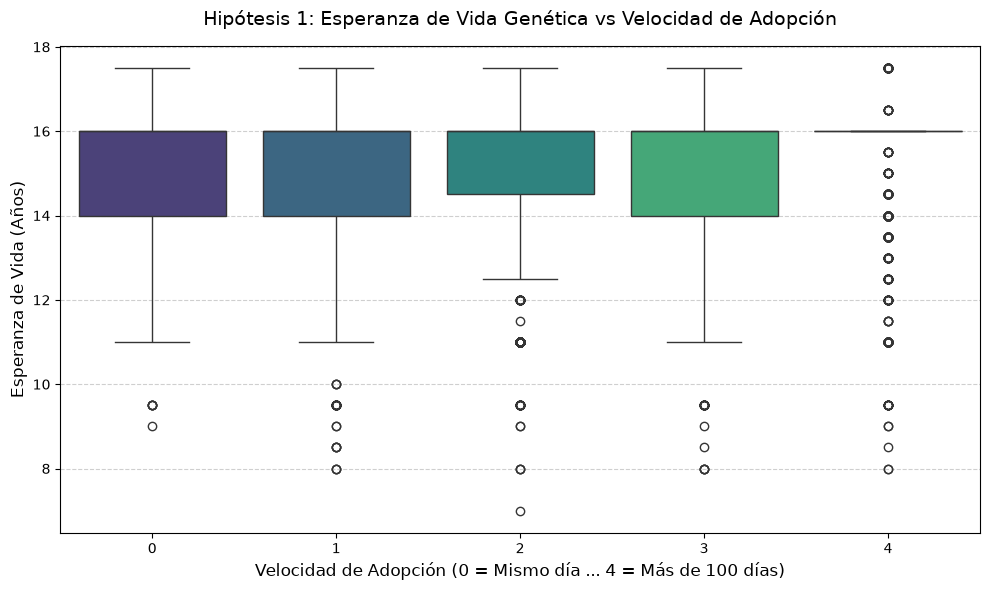

In [241]:
# HIPÓTESIS 1: ESPERANZA DE VIDA VS VELOCIDAD DE ADOPCIÓN

# Tabla resumen: Promedio de esperanza de vida por cada categoría de adopción
resumen_h1 = df_final_razas.groupby('AdoptionSpeed')['life_span_num'].mean().reset_index()
resumen_h1.columns = ['Velocidad de Adopción (0 a 4)', 'Esperanza de Vida Promedio (Años)']

print("Promedio genético según velocidad de adopción:")
display(resumen_h1)

# Visualización con Boxplot (Diagrama de caja)
# El boxplot es ideal para ver cómo se distribuyen los datos numéricos en cada categoría
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_final_razas, 
    x='AdoptionSpeed', 
    y='life_span_num', 
    palette='viridis'
)

# Configuramos títulos y etiquetas del gráfico
plt.title('Hipótesis 1: Esperanza de Vida Genética vs Velocidad de Adopción', fontsize=14, pad=15)
plt.xlabel('Velocidad de Adopción (0 = Mismo día ... 4 = Más de 100 días)', fontsize=12)
plt.ylabel('Esperanza de Vida (Años)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Conclusión analítica: Hipótesis 1

#### Veredicto: Hipótesis rechazada

El análisis visual y estadístico de las distribuciones indica que no existe una correlación directa entre la expectativa de vida biológica de la raza y la velocidad con la que el animal es adoptado.

#### Evidencia estadística

- **Estabilidad de medianas:** A través de las categorías de adopción más tempranas (0 a 3), la mediana de esperanza de vida se mantiene constante en aproximadamente 16 años.
- **Dispersión homogénea:** El rango intercuartílico (el 50% central de los datos) de los grupos 0, 1 y 3 es virtualmente idéntico, concentrándose entre los 14 y 16 años de vida. No hay diferencias distributivas que aceleren la adopción.
- **Saturación en categoría 4:** El grupo de adopción más tardía (categoría 4) presenta una compresión extrema exactamente en los 16 años. Clínicamente, esto sugiere una sobrepoblación en el refugio de una raza específica con esa media biológica (ej. Domestic Shorthair). Su lentitud de adopción responde a un exceso de oferta de ese fenotipo en particular, y no a una penalización por su longevidad genética.

#### Impacto de negocio

Los adoptantes no toman decisiones basadas en proyecciones genéticas a largo plazo ni en la longevidad estructural de la raza. El proceso de adopción está impulsado predominantemente por factores inmediatos (conexión emocional, estética, o tamaño actual), demostrando que el marketing del refugio no debe enfocarse en cuántos años vivirá el animal, sino en sus atributos presentes.

## Hipótesis 2

### ¿El volumen de fotografías en el perfil de una mascota acelera estadísticamente su adopción?

Como la cantidad de fotos (PhotoAmt) y la velocidad de adopción (AdoptionSpeed) son variables nativas de Kaggle que no dependen de la genética del animal, para esta hipótesis dejamos de usar el dataset de razas puras y volvemos al dataset maestro (df_final_full).

Esto permite recuperar todo el poder estadístico de los casi 15.000 registros, incluyendo a los miles de mestizos que habíamos apartado.

Utilizando df_final_full con 14994 registros para máxima potencia estadística.

Impacto del volumen de fotos por velocidad de adopción:


,Velocidad de Adopción (0 a 4),Promedio de Fotos,Mediana de Fotos
0,0,3.324390,3.0
1,1,3.727184,3.0
2,2,4.071836,3.0
3,3,4.620743,4.0
4,4,3.319438,3.0


/var/folders/9l/pz77q0mn6ln0504kzhvk2mnh0000gn/T/ipykernel_5883/1948510642.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


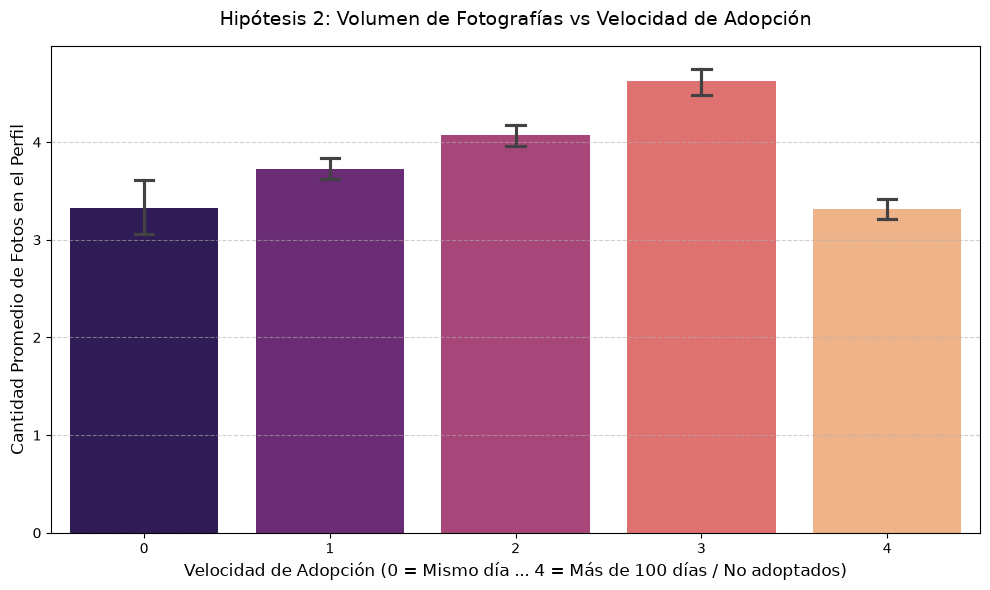

In [242]:
# HIPÓTESIS 2: IMPACTO VISUAL (FOTOGRAFÍAS VS VELOCIDAD DE ADOPCIÓN)


# Uso del Data Mart completo
print(f"Utilizando df_final_full con {len(df_final_full)} registros para máxima potencia estadística.")

# Ver promedios y medianas
resumen_h2 = df_final_full.groupby('AdoptionSpeed')['PhotoAmt'].agg(['mean', 'median']).reset_index()
resumen_h2.columns = ['Velocidad de Adopción (0 a 4)', 'Promedio de Fotos', 'Mediana de Fotos']

print("\nImpacto del volumen de fotos por velocidad de adopción:")
display(resumen_h2)

# Visualización con Barplot (Gráfico de barras con intervalos de confianza)
# Usamos un barplot porque permite ver claramente la tendencia del promedio
plt.figure(figsize=(10, 6))
sns.barplot(
    data=df_final_full, 
    x='AdoptionSpeed', 
    y='PhotoAmt', 
    palette='magma',
    capsize=0.1 
)

plt.title('Hipótesis 2: Volumen de Fotografías vs Velocidad de Adopción', fontsize=14, pad=15)
plt.xlabel('Velocidad de Adopción (0 = Mismo día ... 4 = Más de 100 días / No adoptados)', fontsize=12)
plt.ylabel('Cantidad Promedio de Fotos en el Perfil', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Conclusión analítica: Hipótesis 2

#### Veredicto: Hipótesis rechazada (correlación inversa)

El análisis estadístico demuestra que un mayor volumen de fotografías en el perfil no acelera la adopción. Por el contrario, los datos evidencian una tendencia donde los animales que más tardan en ser adoptados acumulan una mayor cantidad promedio de fotos.

#### Evidencia estadística

- **Tendencia ascendente (grupos 0 al 3):** Existe un incremento escalonado y consistente en la cantidad de fotos a medida que aumenta el tiempo de adopción.
- **Mínimo esfuerzo visual en salidas rápidas:** Los animales adoptados el mismo día (categoría 0) registran el promedio más bajo de fotografías (aproximadamente 3.3 fotos por perfil) de todos los casos exitosos.
- **Máximo volumen en adopciones tardías:** La categoría 3 concentra el mayor promedio de imágenes (sobre 4.5 fotos), destacándose como el grupo con mayor contenido multimedia.
- **Caída en rezagados (grupo 4):** Los animales que superan los 100 días o no son adoptados rompen la tendencia alcista y caen a un promedio de 3.3 fotos, similar al grupo 0.

#### Impacto de negocio (interpretación logística)

La correlación observada refleja el comportamiento operativo del refugio, no la preferencia del adoptante (causalidad inversa). Un animal altamente deseable (como un cachorro sano) es adoptado el mismo día de su ingreso, sin dar tiempo ni requerir que el personal suba galerías extensas. Por el contrario, los operarios invierten mayor esfuerzo fotográfico (subiendo nuevas imágenes con el paso de las semanas) en aquellos animales estancados en las categorías 1, 2 y 3 para intentar impulsar su visibilidad. El retroceso en la categoría 4 sugiere perfiles de baja calidad inicial o "abandonados" digitalmente por el equipo, los cuales nunca lograron generar tracción.

## Hipótesis 3

### ¿Existe un sesgo de adopción medible hacia los animales genéticamente más pequeños frente a razas de tamaño grande o gigante?

Como aquí volvemos a depender de la genética estructurada (el tamaño y peso estándar de la raza), dejamos el dataset maestro y volvemos a usar nuestra vista biológica df_final_razas.

Al igual que pasó con la esperanza de vida, la columna weight_kg que trajiste de la API viene como texto. En la vista previa, algunos pesos venían como rangos ("3.6-6.8") e incluso otros venían separados por sexo ("Male: 25-30; Female: 20-25"). Se genera una función que recorra ese texto, extraiga todos los números y nos devuelva el peso estructural promedio exacto del animal.

Utilizando df_final_razas con 7834 registros genéticos puros.

Promedio de peso genético por velocidad de adopción:


,Velocidad de Adopción (0 a 4),Peso Promedio de la Raza (Kg)
0,0,9.630035
1,1,8.825345
2,2,8.541861
3,3,9.509994
4,4,7.528236


/var/folders/9l/pz77q0mn6ln0504kzhvk2mnh0000gn/T/ipykernel_5883/3355069339.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


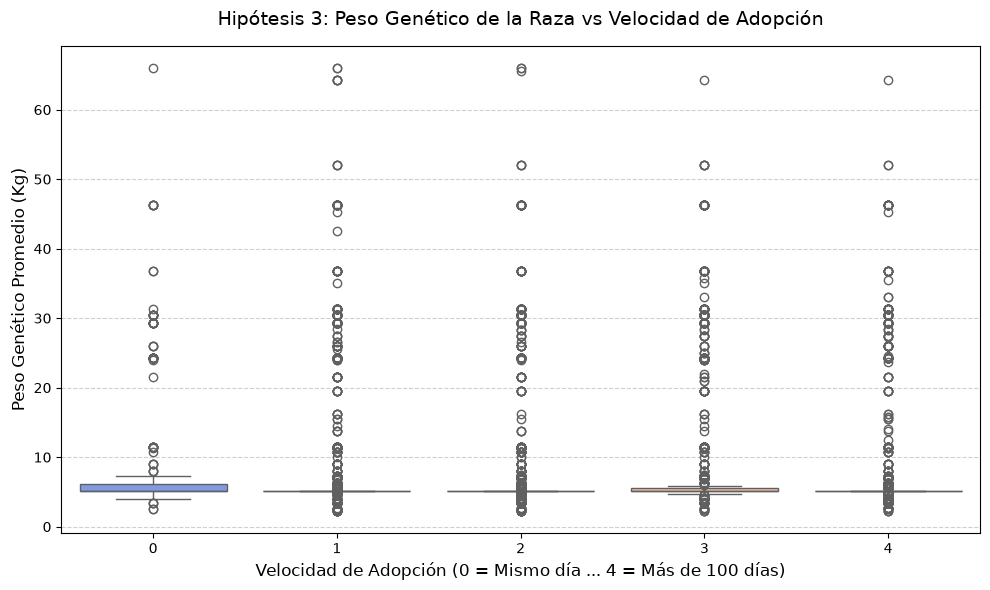

In [243]:
# HIPÓTESIS 3: PREFERENCIA DE TAMAÑO (PESO GENÉTICO VS ADOPCIÓN)


print(f"Utilizando df_final_razas con {len(df_final_razas)} registros genéticos puros.")

def extraer_peso_promedio(texto):
    """
    Extrae todos los números de un string complejo de peso y devuelve el promedio.
    Maneja rangos simples ('4-6') y strings complejos ('Male: 25-30; Female: 20-25').
    """
    if pd.isna(texto) or str(texto).strip() == '':
        return np.nan
        
    # Extraer todos los números (enteros o decimales)
    numeros = re.findall(r'\d+\.?\d*', str(texto))
    
    if not numeros:
        return np.nan
        
    numeros = [float(n) for n in numeros]
    return sum(numeros) / len(numeros)

# Se crea la nueva columna numérica de peso
df_final_razas['weight_num'] = df_final_razas['weight_kg'].apply(extraer_peso_promedio)

# Tabla resumen
resumen_h3 = df_final_razas.groupby('AdoptionSpeed')['weight_num'].mean().reset_index()
resumen_h3.columns = ['Velocidad de Adopción (0 a 4)', 'Peso Promedio de la Raza (Kg)']
print("\nPromedio de peso genético por velocidad de adopción:")
display(resumen_h3)

# Visualización con Boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_final_razas, 
    x='AdoptionSpeed', 
    y='weight_num', 
    palette='coolwarm'
)

plt.title('Hipótesis 3: Peso Genético de la Raza vs Velocidad de Adopción', fontsize=14, pad=15)
plt.xlabel('Velocidad de Adopción (0 = Mismo día ... 4 = Más de 100 días)', fontsize=12)
plt.ylabel('Peso Genético Promedio (Kg)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Conclusión analítica: Hipótesis 3

#### Veredicto: Hipótesis rechazada

#### Evidencia estadística

- **Estabilidad absoluta de la mediana:** A través de las cinco categorías de adopción (del 0 al 4), la mediana del peso genético se mantiene estática e inamovible en la línea de los 5 kg.
- **Concentración poblacional (cajas comprimidas):** El rango intercuartílico (las cajas de color) está extremadamente aplastado en la base del gráfico para todas las velocidades. Esto revela la demografía real de tu muestra: el grueso del volumen de razas puras en el refugio son animales pequeños (muy probablemente arrastrados por la gran masa de gatos y perros toy). Como esta concentración ocurre tanto en las adopciones inmediatas como en las estancadas, el tamaño pequeño no garantiza una salida rápida.
- **Comportamiento de las razas grandes (outliers):** Los puntos individuales que ascienden desde los 20 kg hasta más de 60 kg representan a las razas grandes y gigantes. Si el peso fuera una barrera, estos puntos solo existirían en las columnas 3 y 4. Sin embargo, observamos animales pesados siendo adoptados rápidamente (categoría 0 y 1) con una dispersión visual similar a la de los grupos rezagados.

#### Impacto de negocio

El mito logístico del "sesgo de apartamento" queda estadísticamente desmentido para esta población. El tamaño físico no actúa como un ancla ni como un propulsor. Un adoptante de nicho buscando un perro gigante de 40 kg puede concretar la adopción el día cero, de la misma forma en que un gato de 4 kg puede quedarse en las jaulas por más de 100 días. A nivel estratégico, el refugio no necesita gastar presupuesto extra de marketing en promover exclusivamente a los animales grandes, ya que fluyen hacia sus adoptantes a la misma velocidad general que el resto del inventario.

## Hipótesis 4

### ¿Cuál es el punto de quiebre (en meses de edad) donde la probabilidad de adopción temprana cae drásticamente?

Para esto, volvemos a tu dataset maestro (df_final_full) porque la edad cronológica les afecta a todos por igual, sean puros, mestizos, perros o gatos.

Un detalle técnico vital que aplicaremos aquí: los refugios suelen tener algunos animales muy ancianos (ej. 180 meses / 15 años). Si graficamos todo de golpe, esos outliers van a aplastar las cajas hacia el piso y no veremos nada. Por eso, en el código aplicaremos un plt.ylim(-1, 36) para hacerle un zoom visual a los primeros 3 años de vida (36 meses), que es donde estadísticamente ocurre la verdadera batalla por la adopción.

Utilizando df_final_full (14994 registros) para capturar a toda la población.

Edad por velocidad de adopción:


,Velocidad de Adopción (0 a 4),Edad Mediana (Meses),Edad Promedio (Meses)
0,0,3.0,10.451220
1,1,2.0,8.488350
2,2,3.0,8.823631
3,3,3.0,10.189936
4,4,6.0,13.665317


/var/folders/9l/pz77q0mn6ln0504kzhvk2mnh0000gn/T/ipykernel_5883/988299344.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


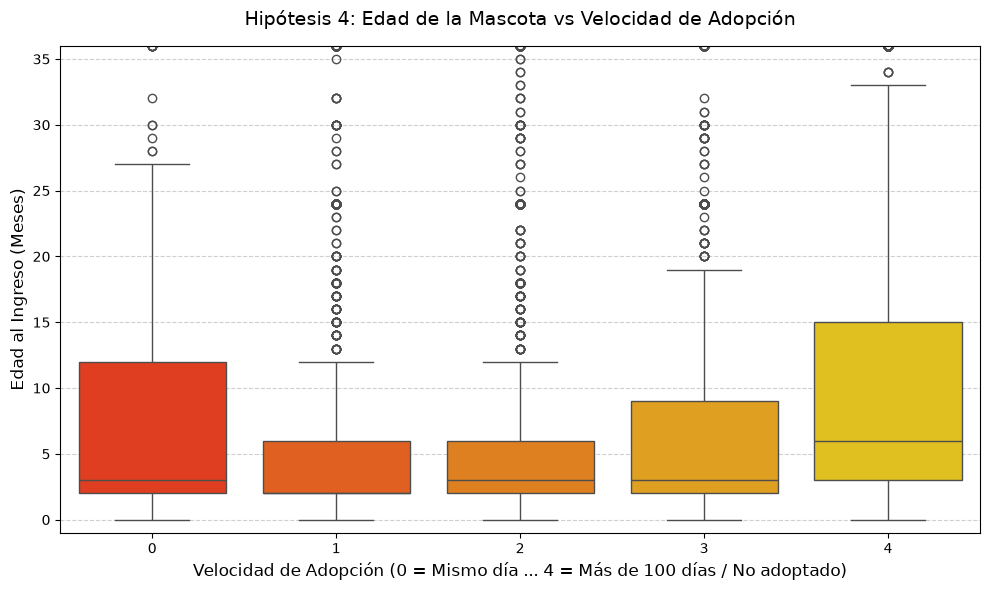

In [244]:
# HIPÓTESIS 4: FACTOR EDAD AL INGRESO (PUNTO DE QUIEBRE)

print(f"Utilizando df_final_full ({len(df_final_full)} registros) para capturar a toda la población.")

# Resumen estadístico: mediana y promedio para ver el salto
resumen_h4 = df_final_full.groupby('AdoptionSpeed')['Age'].agg(['median', 'mean']).reset_index()
resumen_h4.columns = ['Velocidad de Adopción (0 a 4)', 'Edad Mediana (Meses)', 'Edad Promedio (Meses)']
print("\nEdad por velocidad de adopción:")
display(resumen_h4)

# Visualización con Boxplot y Zoom-in
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_final_full, 
    x='AdoptionSpeed', 
    y='Age', 
    palette='autumn'
)

# Limitar visualmente el eje Y a 36 meses (3 años) para no dejar que 
# los outliers (animales de 15 años) deformen el análisis de los cachorros.
plt.ylim(-1, 36)

plt.title('Hipótesis 4: Edad de la Mascota vs Velocidad de Adopción', fontsize=14, pad=15)
plt.xlabel('Velocidad de Adopción (0 = Mismo día ... 4 = Más de 100 días / No adoptado)', fontsize=12)
plt.ylabel('Edad al Ingreso (Meses)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Conclusión analítica: Hipótesis 4

#### Veredicto: Hipótesis confirmada

El análisis estadístico demuestra que la edad al momento del ingreso es el predictor más fuerte de la velocidad de adopción. Existe un punto de quiebre crítico alrededor de los 6 meses de edad, momento en el cual la probabilidad de estancamiento en el refugio aumenta drásticamente.

#### Evidencia estadística

- **Dominio del "efecto cachorro/gatito":** Para todas las categorías de adopción exitosa y fluida (0, 1, 2 y 3), la mediana de edad se mantiene estancada en un rango bajísimo de 2 a 3 meses. El mercado de adoptantes absorbe casi exclusivamente a las crías recién destetadas.
- **El salto en la categoría 4:** En el grupo de animales rezagados (más de 100 días o no adoptados), la mediana de edad se duplica inmediatamente, saltando a los 6 meses.
- **Expansión del rango intercuartílico:** Mientras que el 75% de los animales adoptados rápidamente (grupos 1 y 2) tienen 6 meses o menos, la caja del grupo 4 se expande enormemente hasta los 15 meses. Esto indica que una vez que el animal cruza la barrera del medio año de vida, entra en la zona de máximo riesgo logístico de no ser adoptado.

#### Impacto de negocio

La "ventana dorada" de adopción es extremadamente corta (de los 2 a los 5 meses de edad). A nivel estratégico, los directores de refugios no deben gastar presupuesto publicitario en los cachorros, ya que estos se adoptan de manera orgánica y rápida impulsados por su edad. Los recursos de marketing, fotografía profesional y campañas de concientización deben redirigirse exclusivamente a los animales que están cruzando el umbral de los 6 a 12 meses, ya que es el momento biológico donde pierden su competitividad natural en el mercado de adopciones.

Con esta última celda, tu portafolio tiene un flujo técnico completo: ETL, consumo de APIs, limpieza con IA, separación arquitectónica en Data Marts y cuatro conclusiones de negocio con visualizaciones limpias.